# 04 · ML deep dive
Feature ablation, Optuna tuning, neural network, ensemble, quantile forecast, spike/negative-price classifier, SHAP, Diebold-Mariano and drift monitoring. All runs are logged in MLflow (`mlflow ui --backend-store-uri sqlite:///mlflow.db`).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)


## 1. Feature ablation (last 12 CV months)

,dropped,n_features,MAE,delta_MAE
0,(none - full model),51,20.13,0.00
1,calendar,41,22.35,2.23
2,price_lags,39,21.41,1.28
3,neighbours,42,20.30,0.18
4,system_forecasts,44,20.27,0.14
5,flows,50,20.02,-0.11
6,weather,39,20.76,0.63


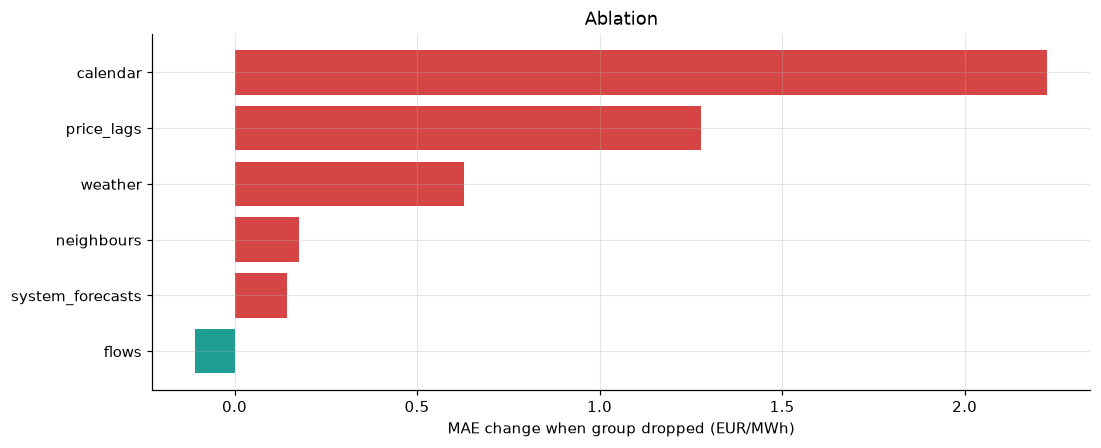

Takeaway: removing 'calendar' hurts most (+2.23 EUR/MWh).


In [2]:
ab = pd.read_csv(R / "ablation.csv"); display(ab.round(3))
a = ab.iloc[1:].sort_values("delta_MAE"); plt.barh(a.dropped, a.delta_MAE, color=[RED if v > 0 else TEAL for v in a.delta_MAE])
plt.xlabel("MAE change when group dropped (EUR/MWh)"); plt.title("Ablation"); plt.show()
print(f"Takeaway: removing '{a.dropped.iloc[-1]}' hurts most ({a.delta_MAE.iloc[-1]:+.2f} EUR/MWh).")

## 2. Optuna tuning
TPE sampler, fixed seed, objective = MAE over the 4 most recent CV months (expanding window). The holdout is never seen.

50 trials


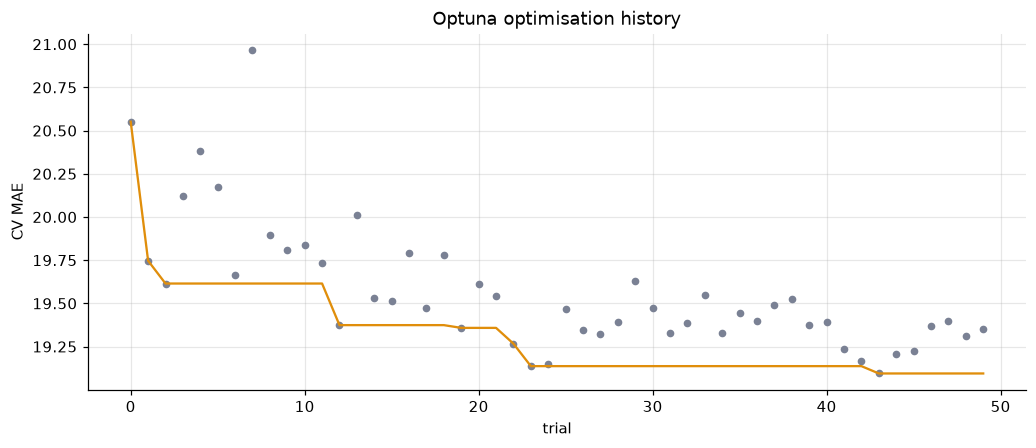

{'num_leaves': 81, 'learning_rate': 0.017171937220483675, 'n_estimators': 1200, 'min_child_samples': 11, 'colsample_bytree': 0.9266320317157204, 'subsample': 0.7326211361230698, 'reg_alpha': 2.282456718722443, 'reg_lambda': 9.126204123130384}


In [3]:
ot = pd.read_csv(R / "optuna_trials.csv"); print(len(ot), "trials")
plt.plot(ot.number, ot.value, "o", color=GREY, ms=4); plt.plot(ot.number, ot.value.cummin(), color=ACC)
plt.xlabel("trial"); plt.ylabel("CV MAE"); plt.title("Optuna optimisation history"); plt.show()
print(json.loads((ROOT / "models/lgbm_best_params.json").read_text()))

## 3-4. Neural network and ensemble

In [4]:
ho = pd.read_csv(R / "metrics_holdout.csv").set_index("model"); cv = pd.read_csv(R / "metrics_cv.csv").set_index("model")
cols = ["MAE", "RMSE", "MAE_fold_mean", "MAE_fold_std", "skill_vs_best_naive", "DM_stat", "DM_p", "significant_5pct"]
print("CV (mean ± sd across monthly folds)"); display(cv[cols].round(3))
print("Holdout"); display(ho[cols].round(3))
print("Ensemble weights (fitted on CV only):", json.loads((R / "ensemble_weights.json").read_text()))
print(f"Takeaway: MLP MAE {ho.loc['mlp','MAE']:.2f} vs LightGBM {ho.loc['lightgbm','MAE']:.2f}; "
      f"ensemble {ho.loc['ensemble','MAE']:.2f} on the holdout.")

CV (mean ± sd across monthly folds)


,MAE,RMSE,MAE_fold_mean,MAE_fold_std,skill_vs_best_naive,DM_stat,DM_p,significant_5pct
model,,,,,,,,
naive_d1,28.95,49.86,28.95,7.60,0.00,NaN,NaN,NaN
naive_w1,32.86,57.82,32.83,10.88,-0.14,3.72,0.00,False
ridge,24.16,39.94,24.16,6.75,0.17,-9.09,0.00,True
lightgbm,22.84,41.04,22.85,6.94,0.21,-10.16,0.00,True
lightgbm_capacity,23.15,41.32,23.15,6.86,0.20,-9.48,0.00,True
lightgbm_fuels,23.11,41.16,23.11,6.78,0.20,-9.55,0.00,True
lightgbm_level,23.68,41.08,23.68,7.70,0.18,-8.75,0.00,True
mlp,23.55,41.10,23.54,6.54,0.19,-8.82,0.00,True
ensemble,22.32,39.60,22.32,6.54,0.23,-11.63,0.00,True


Holdout


,MAE,RMSE,MAE_fold_mean,MAE_fold_std,skill_vs_best_naive,DM_stat,DM_p,significant_5pct
model,,,,,,,,
naive_d1,30.84,43.48,30.86,2.92,0.00,NaN,NaN,NaN
naive_w1,39.96,52.76,39.92,10.55,-0.30,2.62,0.01,False
ridge,27.93,36.02,27.93,6.82,0.09,-1.81,0.07,False
lightgbm,30.02,39.45,29.99,9.91,0.03,-0.32,0.75,False
lightgbm_capacity,29.76,39.80,29.73,9.89,0.04,-0.40,0.69,False
lightgbm_fuels,31.80,41.95,31.77,11.68,-0.03,0.30,0.76,False
lightgbm_level,26.39,35.96,26.40,6.24,0.14,-2.72,0.01,True
mlp,40.32,49.32,40.28,16.03,-0.31,2.45,0.02,False
ensemble,31.13,39.82,31.11,10.50,-0.01,0.12,0.91,False


Ensemble weights (fitted on CV only): {'lightgbm': 0.55, 'ridge': 0.15, 'mlp': 0.3}
Takeaway: MLP MAE 40.32 vs LightGBM 30.02; ensemble 31.13 on the holdout.


On tabular data with strong, monotone hand-made features, gradient boosting usually matches or beats a small MLP: trees handle heterogeneous scales, missing values and threshold effects (e.g. residual load above which thermal units set the price) natively, while the MLP needs more data to learn them.

### Skill with 95 % intervals and regime robustness
Skill = 1 - MAE / MAE(naive). Intervals: moving-block bootstrap over delivery days (7-day blocks). Candidate variants and the adoption rule were fixed in advance (see `src/robust_experiment.py`): a variant replaces the baseline only if CV MAE is >= 0.1 lower and Diebold-Mariano p < 0.05 on the CV months.

split,cv,holdout
variant,,
ridge,"+16.5% [+13%, +19%]","+9.4% [+0%, +20%]"
lightgbm,"+21.1% [+17%, +24%]","+2.7% [-10%, +19%]"
ensemble,"+22.9% [+19%, +26%]","-1.0% [-14%, +15%]"
mlp,"+18.7% [+15%, +22%]","-30.8% [-51%, -8%]"
lightgbm_level,"+18.2% [+14%, +22%]","+14.4% [+4%, +25%]"
lightgbm_blend,"+20.8% [+17%, +24%]","+14.1% [+4%, +25%]"
lightgbm_guarded,"+19.8% [+16%, +23%]","+11.4% [+2%, +21%]"
lightgbm_levelshape,"+16.8% [+12%, +21%]","+13.9% [+5%, +23%]"
lightgbm_linbase,"+19.6% [+16%, +23%]","+9.8% [-3%, +22%]"


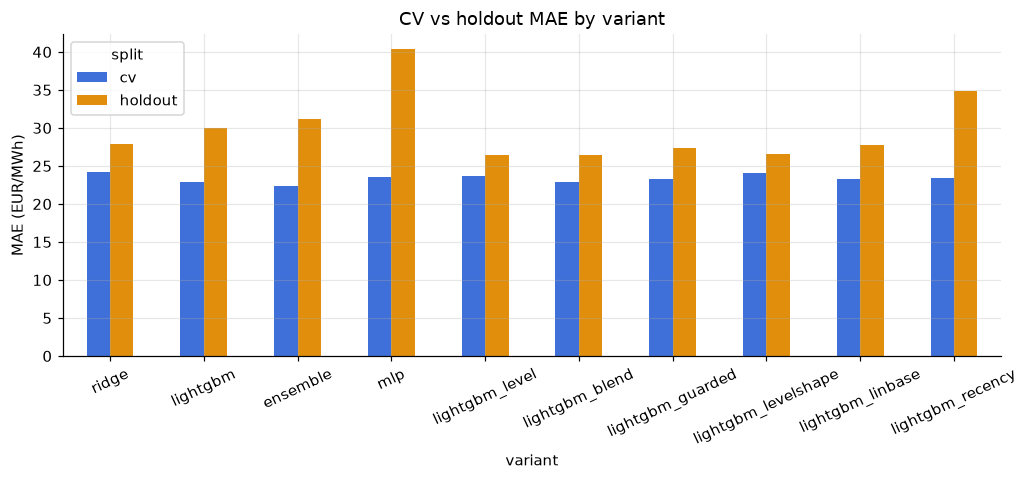

Chosen by the rule: lightgbm


In [5]:
sc = pd.read_csv(R / "skill_confidence.csv"); rm = pd.read_csv(R / "robust_metrics.csv")
order = ["ridge", "lightgbm", "ensemble", "mlp", "lightgbm_level", "lightgbm_blend", "lightgbm_guarded", "lightgbm_levelshape", "lightgbm_linbase", "lightgbm_recency"]
tab = sc.assign(ci=lambda d: d.apply(lambda r: f"{r.skill:+.1%} [{r.skill_lo:+.0%}, {r.skill_hi:+.0%}]", axis=1)).pivot(index="variant", columns="split", values="ci")
display(tab.reindex([o for o in order if o in tab.index]))
mae = rm.pivot(index="variant", columns="split", values="MAE").reindex([o for o in order if o in set(rm.variant)])
mae.plot.bar(figsize=(11, 3.8), color=[BLUE, ACC]); plt.ylabel("MAE (EUR/MWh)"); plt.title("CV vs holdout MAE by variant"); plt.xticks(rotation=25); plt.show()
print("Chosen by the rule:", json.loads((R / "robust_choice.json").read_text())["variant"])

In [6]:
ep = pd.read_csv(R / "robust_episodes.csv"); display(ep.round(1))

,month,split,price_change,mean_price,naive_d1,lightgbm,lightgbm_level,lightgbm_recency,lightgbm_linbase,lightgbm_levelshape,lightgbm_blend,lightgbm_guarded
0,2024-07,cv,0.70,136.50,44.00,37.40,40.90,37.90,36.00,44.30,38.30,38.80
1,2024-10,cv,-0.30,89.40,26.80,19.00,19.30,18.50,19.30,19.70,19.00,19.00
2,2024-11,cv,0.60,167.80,49.30,45.60,48.90,45.50,45.80,50.40,46.10,49.90
3,2025-03,cv,-0.30,104.40,25.80,25.30,27.90,26.70,23.20,24.70,26.20,25.30
4,2025-04,cv,-0.40,85.00,24.40,18.40,19.50,18.50,18.70,19.30,18.70,18.40
5,2025-05,cv,-0.30,85.40,28.30,20.60,21.00,21.00,20.40,20.80,20.30,20.60
6,2025-10,cv,0.30,121.70,30.70,21.30,21.10,22.30,22.40,21.20,21.00,21.30
7,2025-11,cv,0.30,121.50,23.60,19.20,19.10,18.50,20.00,19.90,18.90,19.20
8,2026-08,holdout,0.40,143.20,27.60,21.40,19.80,22.90,20.00,20.30,19.80,21.40
9,2026-09,holdout,0.40,166.20,33.10,27.80,27.20,30.80,27.40,27.20,26.60,27.80


**Reading it.** No variant meets the rule, so LightGBM stays the headline model. The level-anchored variants lose a little on CV and gain about 3.5 MAE in the October-2026 surge, but in the earlier level-shift episodes they mostly do not help: they are insurance against extrapolation, not a tested improvement. Recency weighting is clearly worse on the holdout. The level/shape candidate was added after the first results were seen.

### Other inputs tested: capacity, fuels, outages
Each optional group must lower CV MAE (last 12 CV months) to enter the model.

In [7]:
fc = json.loads((R / "feature_choice.json").read_text()); display(pd.Series(fc).to_frame("value"))
ox = pd.read_csv(R / "outage_experiment.csv"); display(ox.round(3))
fx = pd.read_csv(R / "fuel_experiment.csv"); display(fx.pivot(index="variant", columns="model", values="MAE").round(2))

,value
months,2025-08..2026-07
cv_mae_base,20.13
rule,greedy: adopt a group iff CV MAE (last 12 CV m...
use_capacity,False
cv_mae_without_capacity,20.13
cv_mae_with_capacity,20.53
use_fuels,False
cv_mae_without_fuels,20.13
cv_mae_with_fuels,20.60


,variant,n_features,MAE,fold_sd,delta_vs_none,months,documents
0,none,51,20.13,3.60,0.00,2025-08..2026-07,849
1,oracle outages (NOT usable: uses later revisions),55,20.17,3.65,0.04,2025-08..2026-07,849
2,"strict outages (leak-free, undercounted)",55,20.09,3.68,-0.04,2025-08..2026-07,849


model,LightGBM,LightGBM · level-adj.
variant,,
all fuel features (11),20.60,21.00
daily TTF (3),20.70,20.97
daily TTF + Brent + carbon,20.39,20.77
daily TTF scale-free (2),20.57,20.87
daily only (Brent + carbon),20.36,20.65
levels only,20.47,20.91
monthly gas + Brent + carbon (8),20.38,20.84
monthly gas only,20.42,20.90
none,20.13,20.68


Interconnector capacities (NTC) and fuel/carbon prices did not pass the rule. Plant outages cannot be used point-in-time from the API (only the latest revision of each document is returned); as an upper bound even perfect (leaky) knowledge of the final outage windows does not improve the forecast.

## 5. Probabilistic forecast (quantile LightGBM 10/50/90)

,split,pinball_q10,share_below_q10,pinball_q50,share_below_q50,pinball_q90,share_below_q90,coverage_10_90,mean_band_width
0,cv,5.12,0.19,11.10,0.48,6.98,0.82,0.62,44.95
1,holdout,6.41,0.06,16.39,0.22,12.28,0.55,0.48,63.44


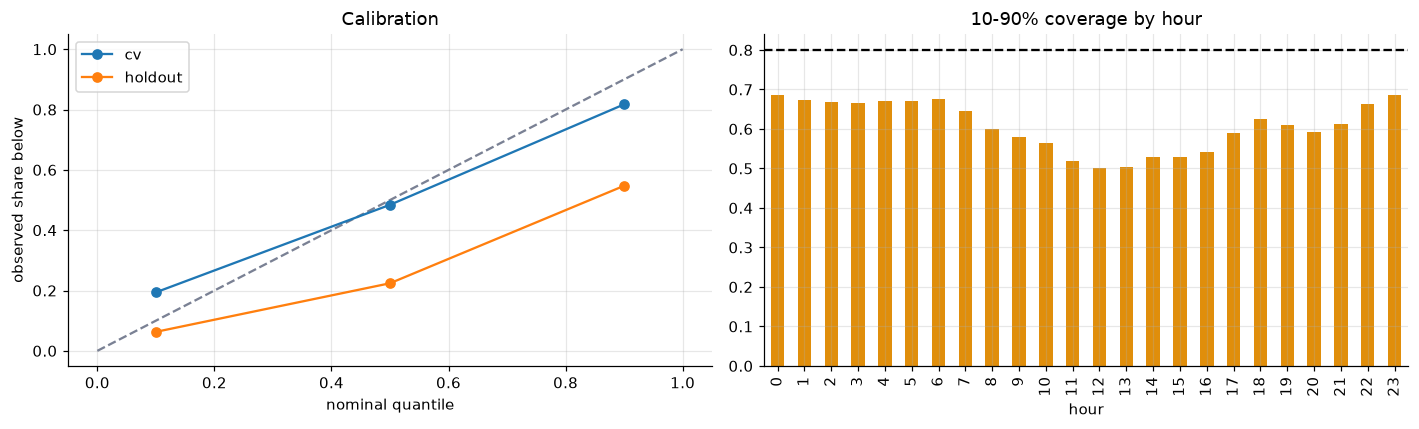

In [8]:
qm = pd.read_csv(R / "quantile_metrics.csv"); display(qm.round(3))
qh = pd.read_csv(R / "quantile_by_hour.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot([0, 1], [0, 1], "--", color=GREY)
for _, r in qm.iterrows(): ax[0].plot([.1, .5, .9], [r.share_below_q10, r.share_below_q50, r.share_below_q90], "o-", label=r.split)
ax[0].set_xlabel("nominal quantile"); ax[0].set_ylabel("observed share below"); ax[0].legend(); ax[0].set_title("Calibration")
qh.coverage_10_90.plot.bar(ax=ax[1], color=ACC); ax[1].axhline(.8, color="k", ls="--"); ax[1].set_title("10-90% coverage by hour")
plt.tight_layout(); plt.show()

### Conformal recalibration
The raw band is too narrow. Each side is widened by the 90 % conformal quantile of its recent out-of-sample misses (days up to D-2 only; window chosen on CV months only).

,variant,split,n,coverage,below,above,width,chosen
0,conformal 30d,cv,16800,0.78,0.11,0.11,63.40,False
1,conformal 30d,holdout,2209,0.75,0.07,0.18,84.36,False
2,conformal 60d,cv,16800,0.79,0.11,0.10,62.53,False
3,conformal 60d,holdout,2209,0.71,0.06,0.23,81.45,False
4,conformal 90d,cv,16800,0.80,0.10,0.10,62.54,False
5,conformal 90d,holdout,2209,0.70,0.06,0.25,80.40,False
6,conformal 180d,cv,16800,0.80,0.10,0.10,62.63,True
7,conformal 180d,holdout,2209,0.68,0.04,0.28,82.25,True
8,conformal expanding,cv,16800,0.81,0.10,0.09,63.55,False
9,conformal expanding,holdout,2209,0.65,0.03,0.32,81.72,False


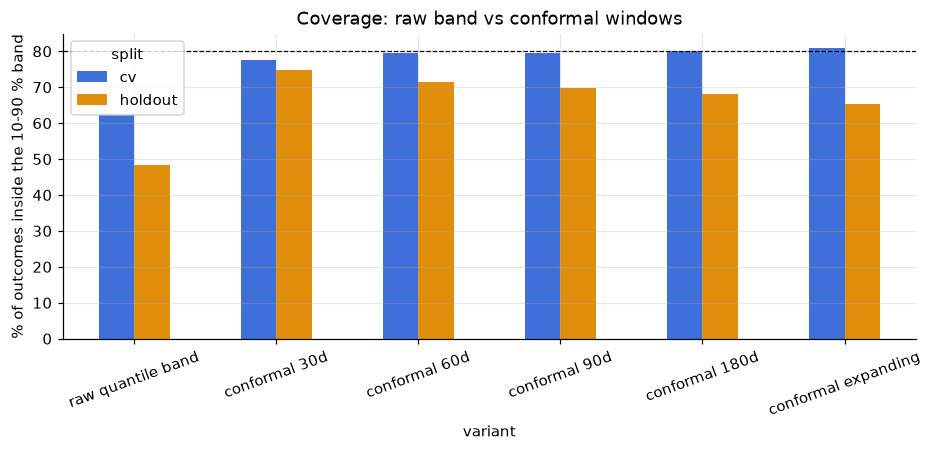

Takeaway: coverage CV 80.0% (target 80 %), holdout 68.1%; the October-2026 surge pushed outcomes above the band.


In [9]:
qc = pd.read_csv(R / "quantile_conformal.csv"); display(qc.round(3))
order = ["raw quantile band"] + [v for v in qc.variant.unique() if v.startswith("conformal")]
piv = qc.pivot(index="variant", columns="split", values="coverage").loc[order]
ax = (100 * piv).plot.bar(figsize=(10, 3.6), color=[BLUE, ACC]); ax.axhline(80, color="k", ls="--", lw=.8)
ax.set_ylabel("% of outcomes inside the 10-90 % band"); ax.set_title("Coverage: raw band vs conformal windows")
plt.xticks(rotation=20); plt.show()
ch = qc[qc.chosen].set_index("split").coverage
print(f"Takeaway: coverage CV {ch['cv']:.1%} (target 80 %), holdout {ch['holdout']:.1%}; "
      "the October-2026 surge pushed outcomes above the band.")

**Business use:** the band is widest in the evening ramp and on solar-driven midday hours; in those hours a trader should hedge or reduce position size rather than rely on the point forecast.

## 6. Spike and negative-price classifier
Targets: (a) price > P95 of each fold's training period (fixed EUR level), (b) **level-relative spike**: price above yesterday's daily mean by more than the training-P95 excess, and (c) price < 0. The fixed definition stops working after the autumn-2026 level shift (43 % of holdout hours); the relative one does not. LightGBM with balanced class weights. Threshold chosen on CV months by minimising **cost = 5 × missed events + 1 × false alarms** (a missed spike = unhedged exposure / missed battery discharge; a false alarm = an unnecessary hedge).

,kind,split,events,base_rate,pr_auc,threshold,precision,recall
0,spike,cv,1280,0.07,0.65,0.28,0.46,0.80
1,spike,holdout,943,0.43,0.90,0.28,0.83,0.86
2,spike_rel,cv,1185,0.07,0.61,0.40,0.46,0.72
3,spike_rel,holdout,169,0.08,0.53,0.40,0.38,0.66
4,cheap,cv,996,0.06,0.75,0.14,0.49,0.83
5,cheap,holdout,46,0.02,0.50,0.14,0.38,0.94
6,negative,cv,346,0.02,0.56,0.10,0.44,0.69
7,negative,holdout,8,0.00,0.11,0.10,0.00,0.00


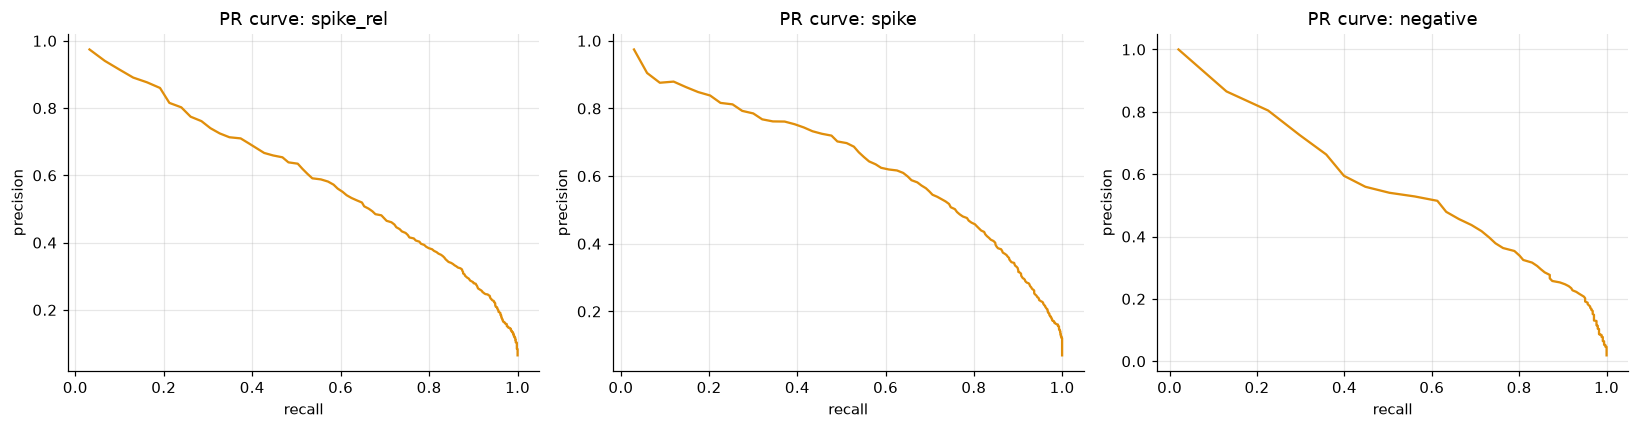

In [10]:
cm = pd.read_csv(R / "classifier_metrics.csv"); display(cm.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, k in enumerate(["spike_rel", "spike", "negative"]):
    f = R / f"classifier_{k}_pr_curve.csv"
    if f.exists():
        c = pd.read_csv(f); ax[i].plot(c.recall, c.precision, color=ACC); ax[i].set_title(f"PR curve: {k}")
        ax[i].set_xlabel("recall"); ax[i].set_ylabel("precision")
plt.tight_layout(); plt.show()

## 7. Explainability (SHAP on the holdout)

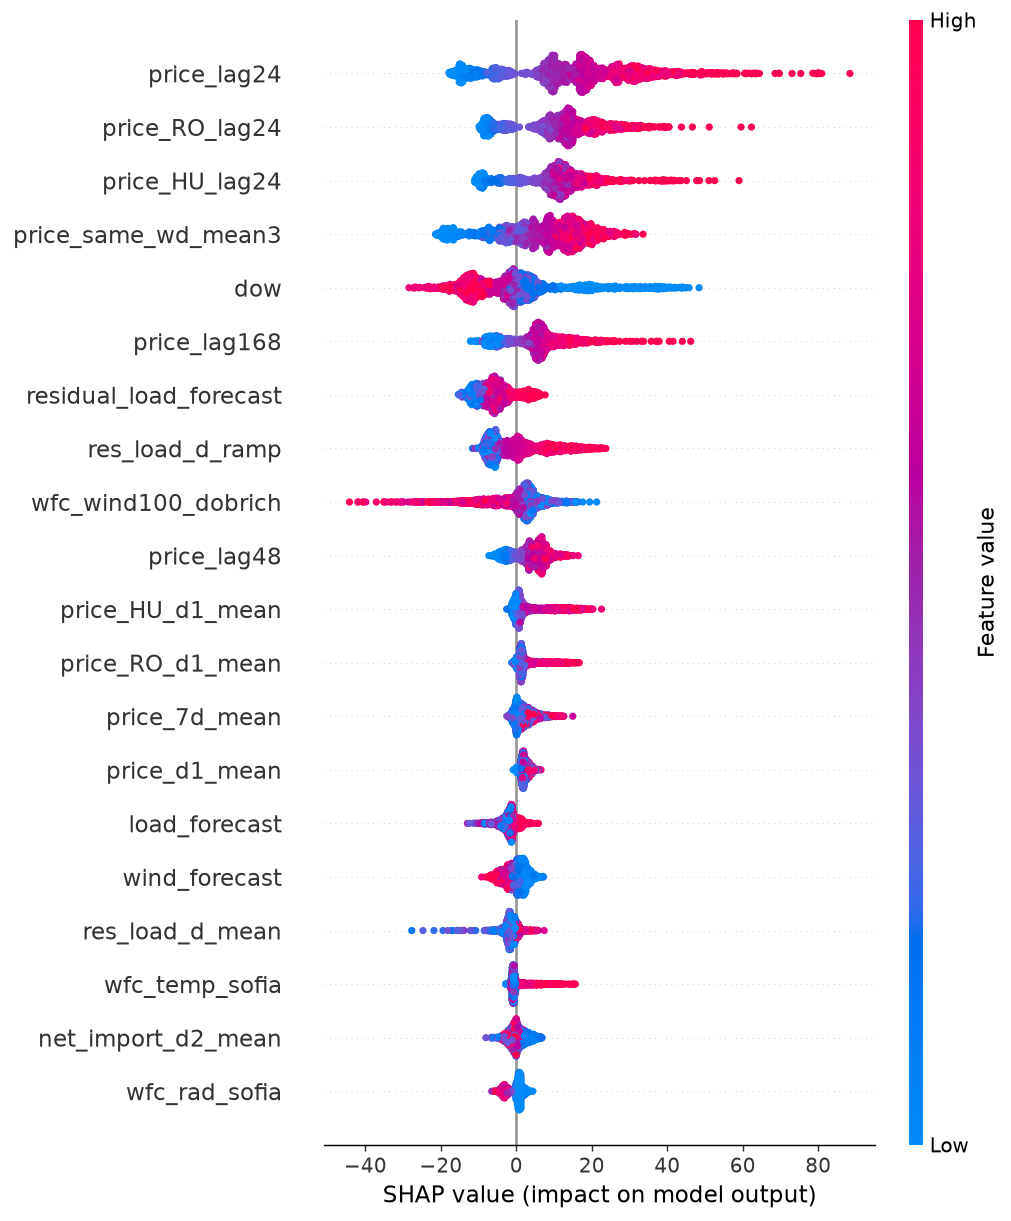

,feature,mean_abs_shap
0,price_lag24,19.65
1,price_RO_lag24,13.90
2,price_HU_lag24,12.42
3,price_same_wd_mean3,11.12
4,dow,9.32
5,price_lag168,7.97
6,residual_load_forecast,6.67
7,res_load_d_ramp,5.99
8,wfc_wind100_dobrich,5.37
9,price_lag48,4.95


In [11]:
display(Image(R / "figures/shap_summary.png", width=750))
display(pd.read_csv(R / "shap_importance.csv").head(12).round(2))

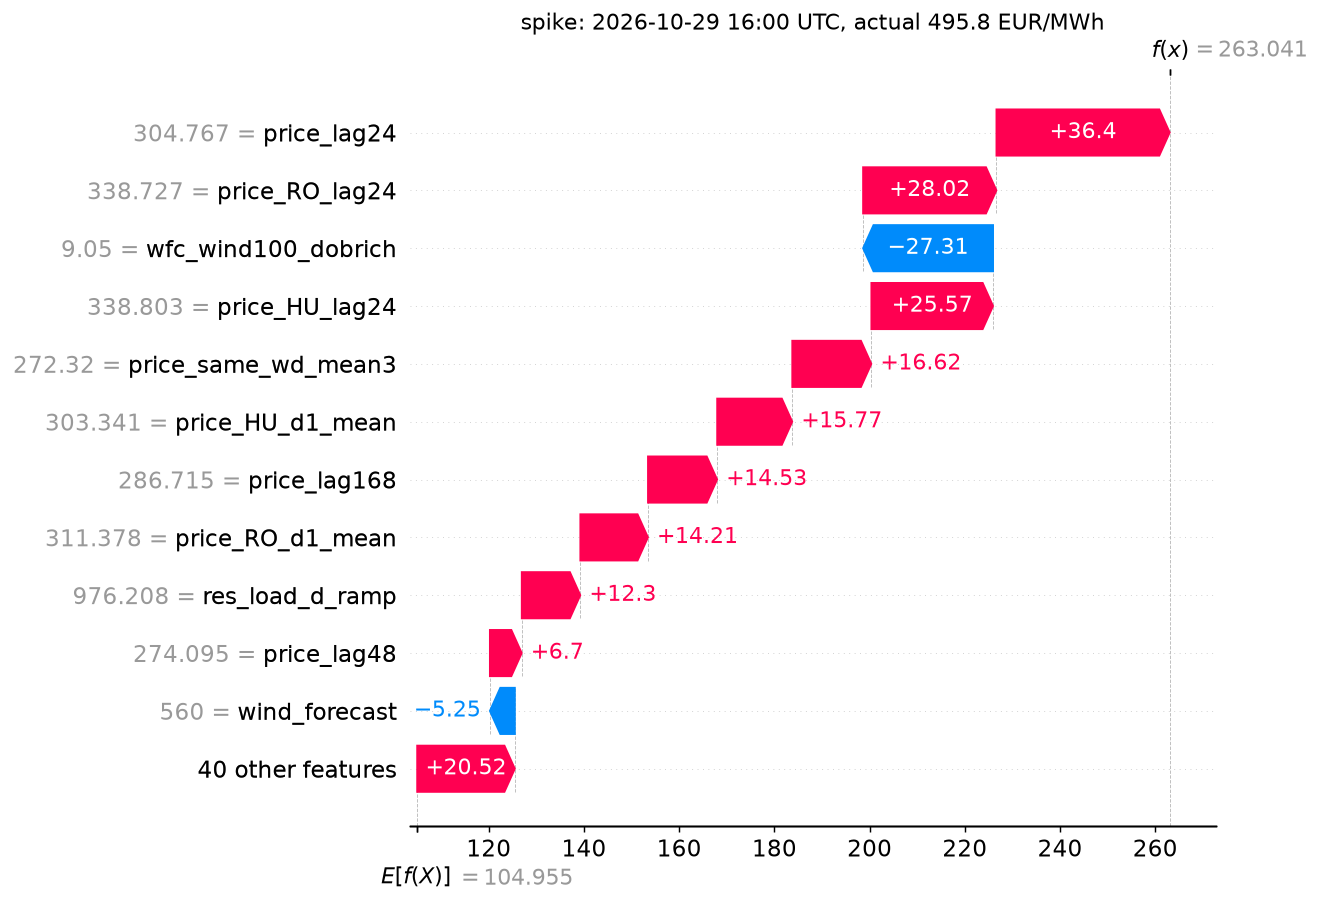

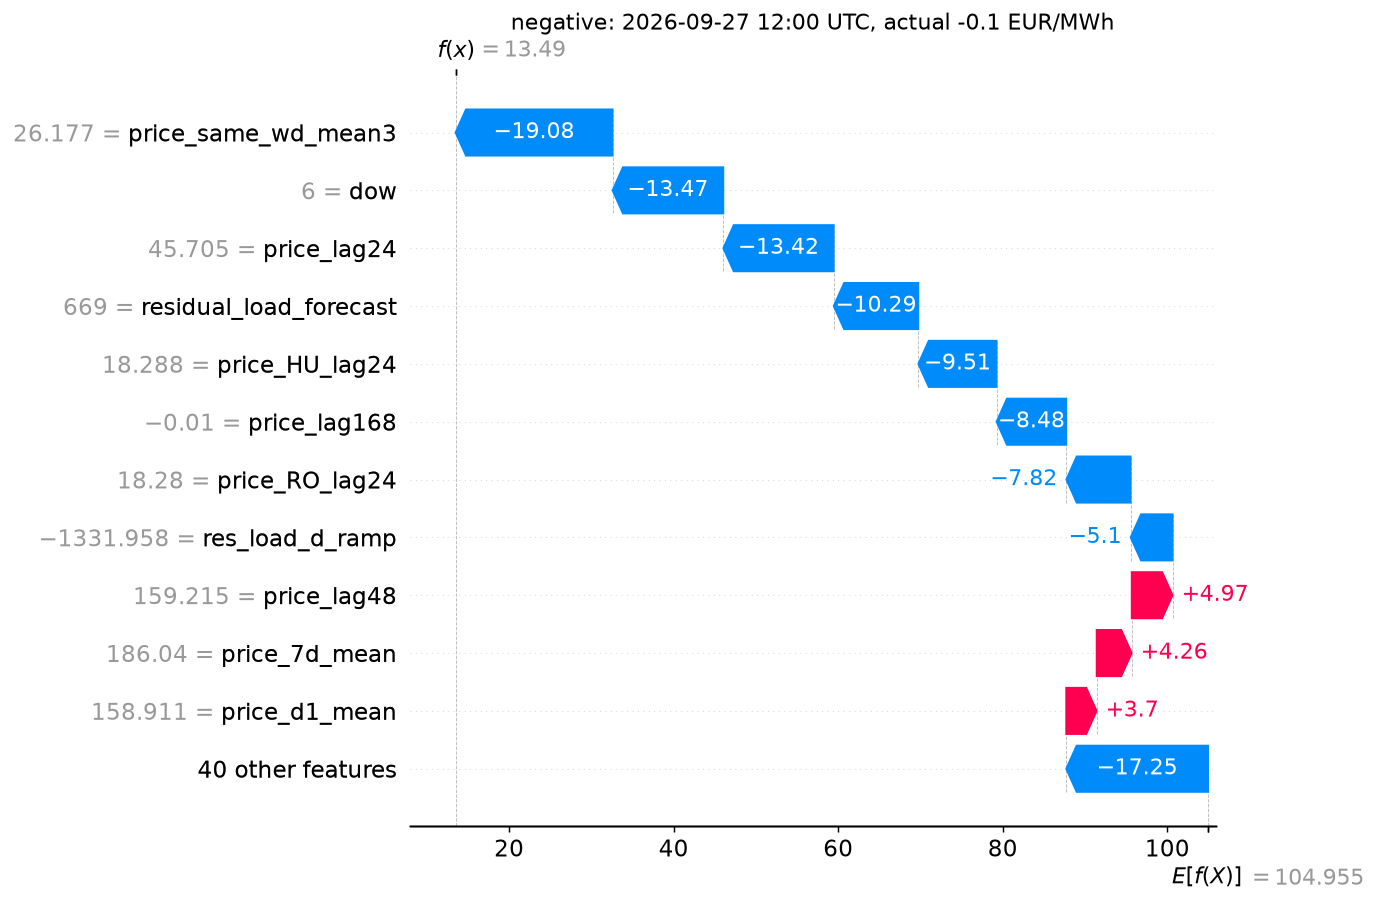

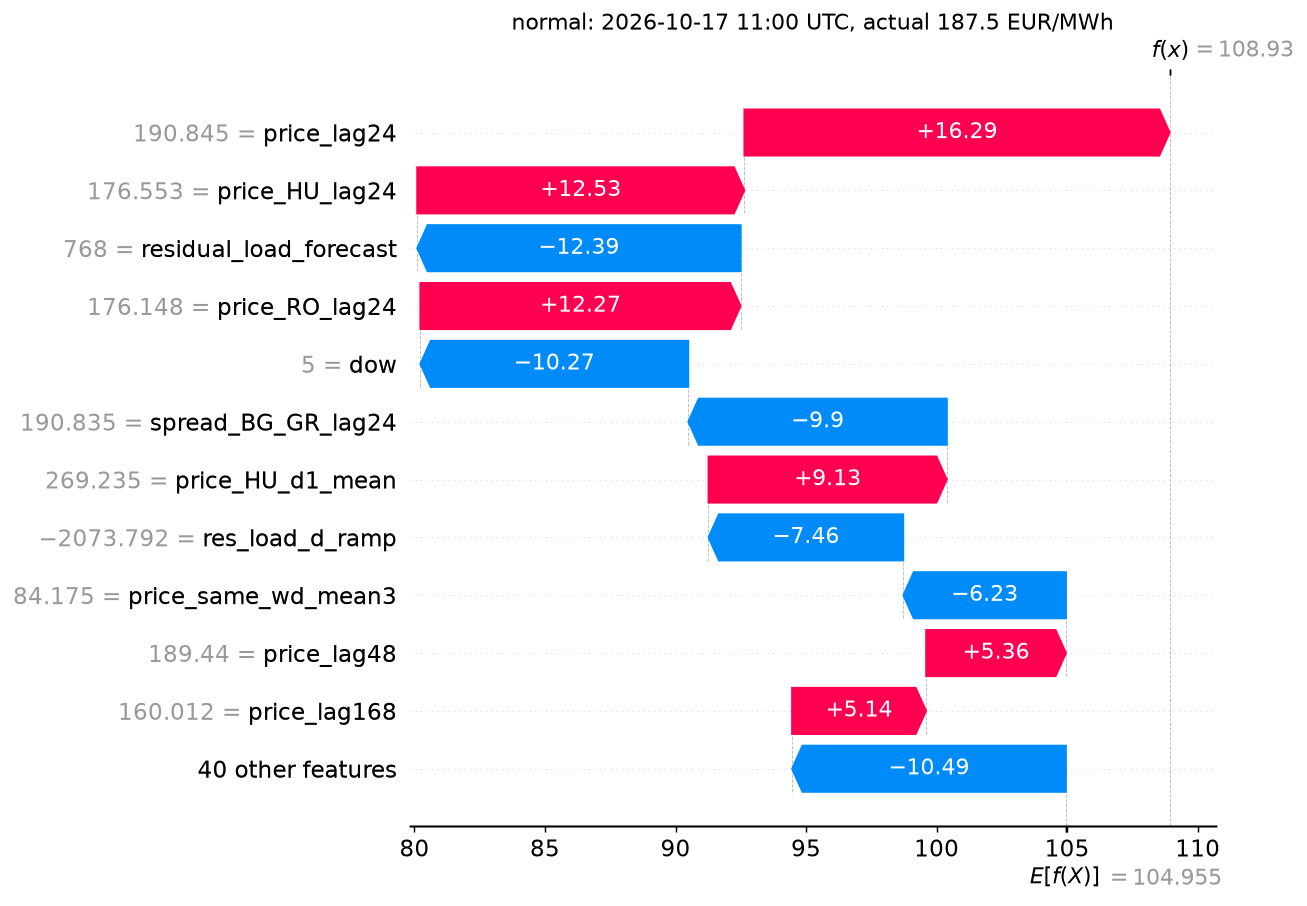

In [12]:
for c in ["spike", "negative", "normal"]:
    f = R / f"figures/shap_waterfall_{c}.png"
    if f.exists(): display(Image(f, width=700))

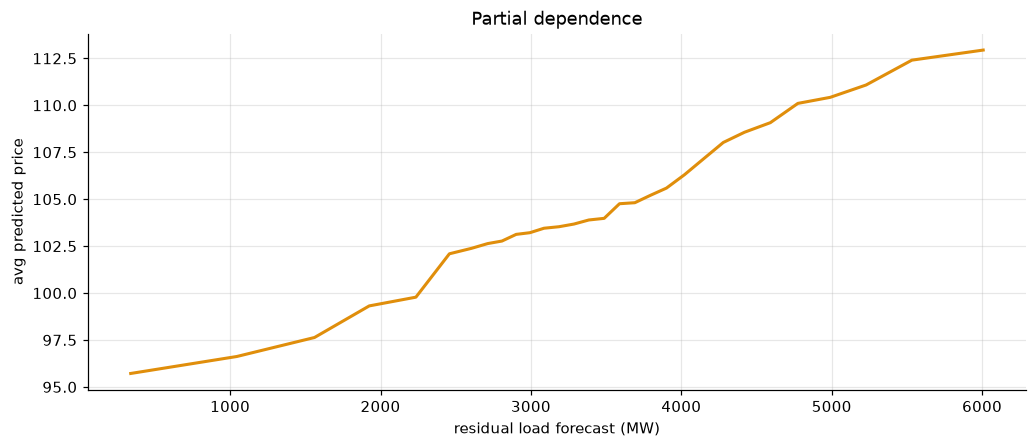

In [13]:
pdp = pd.read_csv(R / "pdp_residual_load.csv"); plt.plot(pdp.iloc[:, 0], pdp.iloc[:, 1], color=ACC, lw=2)
plt.xlabel("residual load forecast (MW)"); plt.ylabel("avg predicted price"); plt.title("Partial dependence"); plt.show()

The drivers line up with market logic: recent price level (yesterday's same hour and daily mean), neighbour prices (market coupling), hour of day and residual load. The partial dependence on residual load is monotone increasing and steepens at high load (merit-order). Nothing points to leakage: no same-day actual quantity is in the feature set.

## 9-10. Monitoring and drift

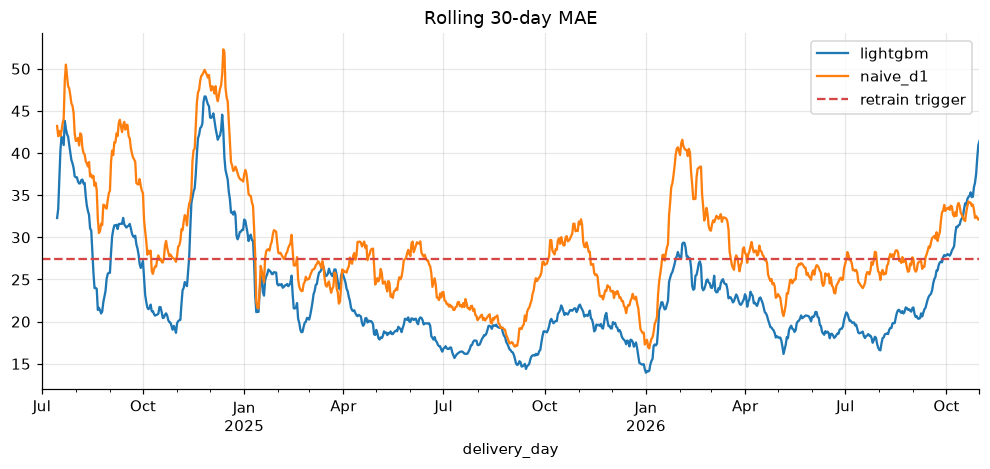

Days with retrain alert: 101


,feature,psi,status
0,load_forecast,0.91,significant shift
1,wind_forecast,0.04,stable
2,solar_forecast,0.41,significant shift
3,residual_load_forecast,0.88,significant shift
4,price_lag24,2.07,significant shift
5,price_RO_lag24,2.24,significant shift
6,fuel_gas_eur_mwh,5.71,significant shift
7,fuel_brent_usd,5.15,significant shift


In [14]:
rm = pd.read_csv(R / "monitor_rolling_mae.csv", index_col=0, parse_dates=True)
ax = rm[["lightgbm", "naive_d1"]].plot(title="Rolling 30-day MAE"); ax.axhline(1.2 * rm.cv_level.iloc[0], color=RED, ls="--", label="retrain trigger")
ax.legend(); plt.show()
print("Days with retrain alert:", int(rm.retrain_alert.sum()))
display(pd.read_csv(R / "monitor_psi.csv").round(3))

**Retraining rule:** retrain monthly on the expanding window; retrain immediately if the 30-day rolling MAE stays more than 20 % above its CV level for 14 consecutive days, or if a key feature's PSI exceeds 0.25.